# Convolution Theorem Approach

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-10.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

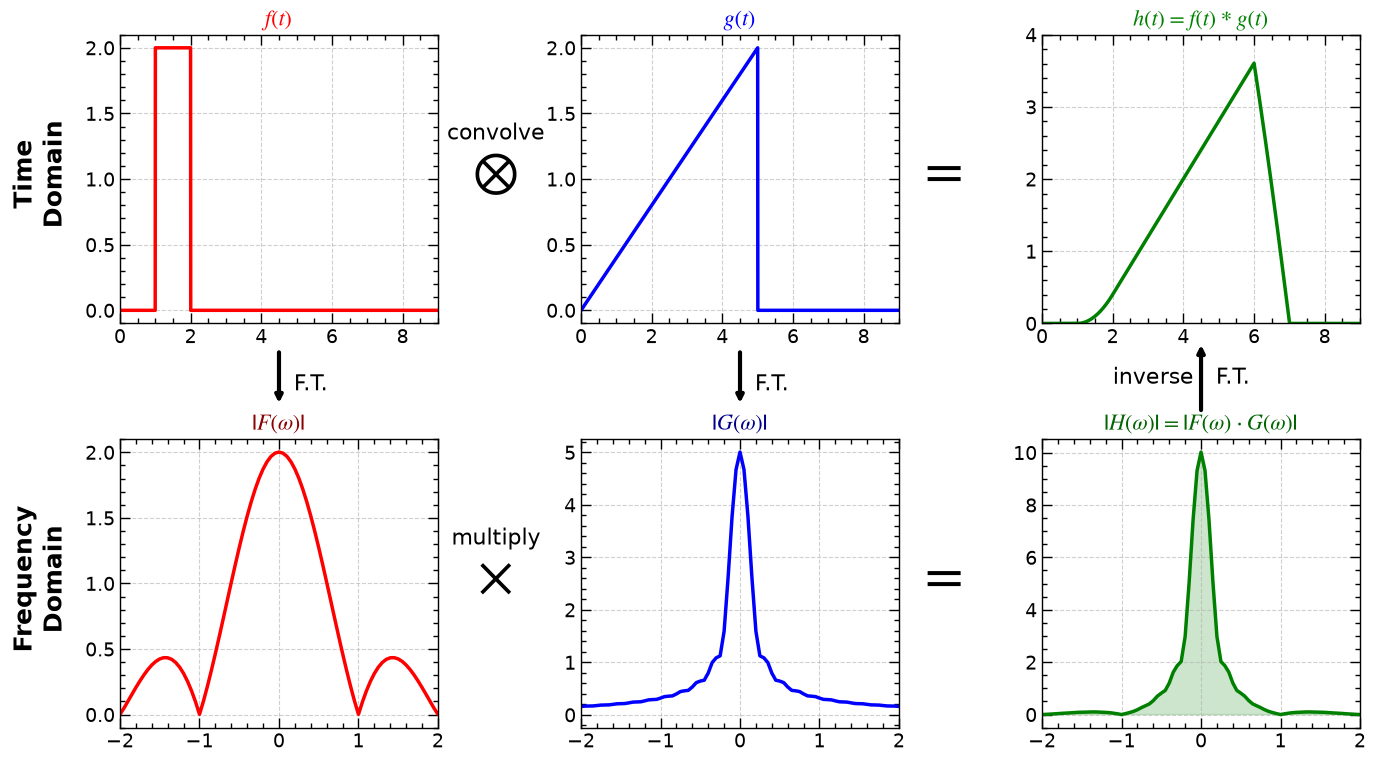

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch

# ==========================================
# 1. Configuration & Styling
# ==========================================
plot_params = {
    'font.size': 14,
    'font.family': 'sans-serif',
    'mathtext.fontset': 'stix',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.5,
    'figure.figsize': (16, 9)
}
plt.rcParams.update(plot_params)

def apply_custom_formatting(ax):
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.minorticks_on()
    ax.tick_params(which='both', direction="in", width=1)
    ax.tick_params(which='major', length=7)
    ax.tick_params(which='minor', length=3.5)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

# ==========================================
# 2. Data Generation
# ==========================================
# Time parameters
N = 4096
T_max = 20.0 
dt = T_max / N
t = np.linspace(0, T_max, N, endpoint=False)

# Functions
f_val = np.where((t >= 1) & (t <= 2), 2.0, 0.0)
g_val = np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

# Frequency Domain Calculations
F_val = np.fft.fft(f_val) * dt
G_val = np.fft.fft(g_val) * dt
H_val = F_val * G_val  # Multiplication in Freq Domain

# Time Domain Result (via IFFT)
h_val = np.real(np.fft.ifft(H_val)) / dt # Scale back

# Shift for plotting centered frequencies
freqs = np.fft.fftfreq(N, d=dt)
freqs_shifted = np.fft.fftshift(freqs)
F_shifted = np.fft.fftshift(np.abs(F_val))
G_shifted = np.fft.fftshift(np.abs(G_val))
H_shifted = np.fft.fftshift(np.abs(H_val))

# ==========================================
# 3. Plotting the Grid
# ==========================================
fig2, axes = plt.subplots(2, 3, figsize=(16, 9))
plt.subplots_adjust(wspace=0.45, hspace=0.4)

# --- Top Row: Time Domain ---
# Plot f(t)
ax_f = axes[0, 0]
ax_f.plot(t, f_val, 'r')
ax_f.set_title(r"$f(t)$", fontsize=16, color='red')
ax_f.set_xlim(0, 9)
apply_custom_formatting(ax_f)

# Plot g(t)
ax_g = axes[0, 1]
ax_g.plot(t, g_val, 'b')
ax_g.set_title(r"$g(t)$", fontsize=16, color='blue')
ax_g.set_xlim(0, 9)
apply_custom_formatting(ax_g)

# Plot h(t)
ax_h = axes[0, 2]
ax_h.plot(t, h_val, 'g')
ax_h.set_title(r"$h(t) = f(t) * g(t)$", fontsize=16, color='green')
ax_h.set_xlim(0, 9)
ax_h.set_ylim(0, 4)
apply_custom_formatting(ax_h)

# --- Bottom Row: Frequency Domain ---
# Plot |F(w)|
ax_F = axes[1, 0]
ax_F.plot(freqs_shifted, F_shifted, 'r')
ax_F.set_title(r"$|F(\omega)|$", fontsize=16, color='darkred')
ax_F.set_xlim(-2, 2)
apply_custom_formatting(ax_F)

# Plot |G(w)|
ax_G = axes[1, 1]
ax_G.plot(freqs_shifted, G_shifted, 'b')
ax_G.set_title(r"$|G(\omega)|$", fontsize=16, color='darkblue')
ax_G.set_xlim(-2, 2)
apply_custom_formatting(ax_G)

# Plot |H(w)|
ax_H = axes[1, 2]
ax_H.plot(freqs_shifted, H_shifted, 'g')
ax_H.fill_between(freqs_shifted, 0, H_shifted, color='green', alpha=0.2)
ax_H.set_title(r"$|H(\omega)| = |F(\omega) \cdot G(\omega)|$", fontsize=16, color='darkgreen')
ax_H.set_xlim(-2, 2)
apply_custom_formatting(ax_H)

# ==========================================
# 4. Adding Flowchart Annotations
# ==========================================

# Helper to draw arrows between axes
def draw_arrow(fig, ax_from, ax_to, text="", color="black"):
    xyA = (0.5, -0.1) # Bottom center of From
    xyB = (0.5, 1.1) # Top center of To
    coordsA = "axes fraction"
    coordsB = "axes fraction"
    con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA=coordsA, coordsB=coordsB,
                          axesA=ax_from, axesB=ax_to,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color=color)
    ax_from.add_artist(con)
    
    # Add text label to the arrow
    if text:
        # Calculate midpoint in display coords to place text
        # Simple hack: place text on the destination axis top
        ax_to.text(0.6, 1.15, text, transform=ax_to.transAxes, 
                   ha='center', va='bottom', fontsize=16, color=color)

# 1. Vertical Arrows (Time <-> Freq)
draw_arrow(fig2, ax_f, ax_F, text="F.T.")
draw_arrow(fig2, ax_g, ax_G, text="F.T.")
# Inverse Transform Arrow (Upwards)
con_inv = ConnectionPatch(xyA=(0.5, 1.1), xyB=(0.5, -0.05), 
                          coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax_H, axesB=ax_h,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color="black")
ax_H.add_artist(con_inv)
ax_h.text(0.35, -0.15, "inverse", transform=ax_h.transAxes, 
          ha='center', va='top', fontsize=16)
ax_h.text(0.6, -0.15, "F.T.", transform=ax_h.transAxes, 
          ha='center', va='top', fontsize=16)

# 2. Horizontal Operations (Mathematical Symbols)
# We place text in Figure coordinates to sit between the subplots
# Get bounding boxes to find positions
r = fig2.canvas.get_renderer()

# Row 1: Convolution
# Between Col 0 and 1
trans = fig2.transFigure
# Approximate positions based on layout
fig2.text(0.36, 0.77, "convolve", fontsize=16, ha='center', va='center') # Convolution
fig2.text(0.36, 0.725, r"$\otimes$", fontsize=40, ha='center', va='center', weight='bold') # Convolution
fig2.text(0.64, 0.725, r"$=$", fontsize=40, ha='center', va='center', weight='bold') # Equals

# Row 2: Multiplication
fig2.text(0.36, 0.32, "multiply", fontsize=16, ha='center', va='center') # Multiply
fig2.text(0.36, 0.275, r"$\times$", fontsize=40, ha='center', va='center', weight='bold') # Multiply
fig2.text(0.64, 0.275, r"$=$", fontsize=40, ha='center', va='center', weight='bold') # Equals

# 3. Row Labels
fig2.text(0.075, 0.725, "Time\nDomain", fontsize=18, weight='bold', rotation=90, va='center', ha='center')
fig2.text(0.075, 0.275, "Frequency\nDomain", fontsize=18, weight='bold', rotation=90, va='center', ha='center')

# plt.suptitle("Convolution Theorem: Time vs. Frequency Domain", fontsize=20, y=0.98)
# plt.tight_layout() # Skip tight_layout as it might mess up manual text placement
plt.show()